# 01 - Exploratory Data Analysis (EDA)
**Project:** Predictive maintenance, NASA C-MAPSS FD001 (Remaining Useful Life)

## 1. Problem description
Each of 100 turbofan engines in the training set is run until it fails, and 21 sensors plus 3 operating settings are recorded every cycle. Given the recent sensor history of an engine, we want to predict its **Remaining Useful Life (RUL)**: how many cycles are left before failure. A good prediction lets maintenance be planned before a failure happens, and a prediction that is too late is more dangerous than one that is too early.

## 2. Task definition
| Item | Definition |
|---|---|
| Input | A window of the last 30 cycles of the sensor and setting readings of one engine (30 x number of kept features) |
| Output | One number: RUL in cycles at the last cycle of the window (regression) |
| Loss | MSE (mean squared error) for training the models |
| Main metric | RMSE in cycles on the 100 test engines. Also reported: MAE, R2 and the NASA asymmetric Score (late predictions are penalised more) |

Training RUL is computed as `last cycle of the engine - current cycle`. The test set gives only the truncated history of each engine, and `PM_truth.csv` gives the true RUL at the last observed cycle.

In [1]:
import os, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

# Find the repository root whether the notebook is run from notebooks/ or from the root
ROOT = os.path.abspath(".." if os.path.basename(os.path.abspath(".")) == "notebooks" else ".")
DATA = os.path.join(ROOT, "data")

# If the CSV files are missing, fetch them with the project's download script
if not os.path.exists(os.path.join(DATA, "PM_train.csv")):
    subprocess.run([sys.executable, os.path.join(DATA, "download_data.py")], check=True)

COLUMNS = ["id", "cycle", "setting1", "setting2", "setting3"] + [f"s{i}" for i in range(1, 22)]
train = pd.read_csv(os.path.join(DATA, "PM_train.csv"))
test = pd.read_csv(os.path.join(DATA, "PM_test.csv"))
truth = pd.read_csv(os.path.join(DATA, "PM_truth.csv"))
print("train", train.shape, "| test", test.shape, "| truth", truth.shape)
assert list(train.columns) == COLUMNS

train (20631, 26) | test (13096, 26) | truth (100, 2)


## 3. Data exploration
### 3.1 Structure and summary statistics

In [2]:
display(train.head())
print("Engines in train:", train["id"].nunique(), "| engines in test:", test["id"].nunique())
print(train.dtypes.value_counts())
display(train.describe().T)

,id,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


Engines in train: 100 | engines in test: 100
float64    22
int64       4
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
id,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
setting1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
s1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
s2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
s3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
s4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
s5,20631.0,14.620000,1.776400e-15,14.6200,14.6200,14.6200,14.6200,14.6200


### 3.2 Target distribution (RUL)

Engine lifetime (cycles):
count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


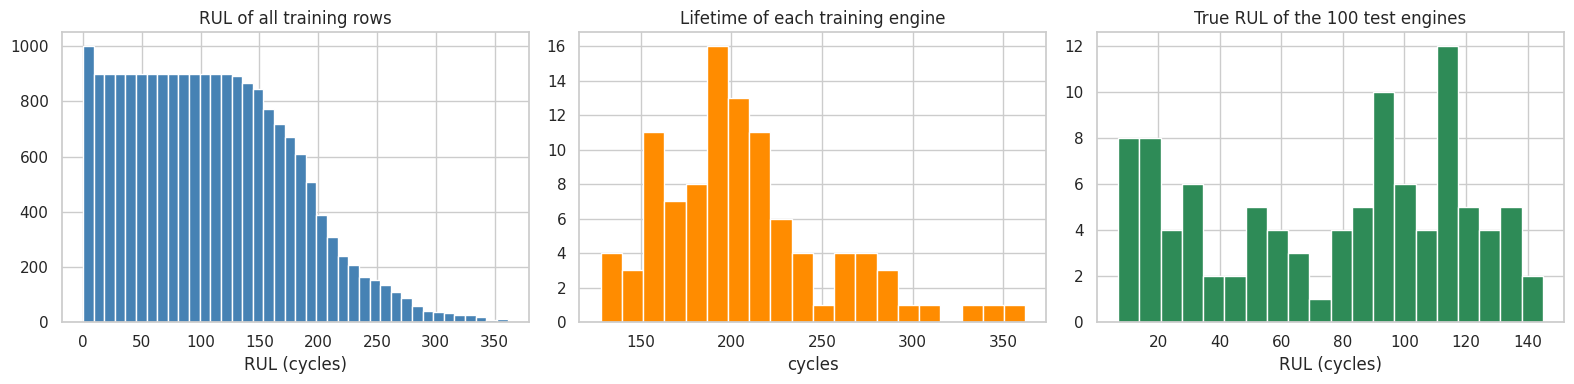

RUL skewness (train rows): 0.5
Test RUL: min 7, median 86, max 145


In [3]:
max_cycle = train.groupby("id")["cycle"].transform("max")
train["RUL"] = max_cycle - train["cycle"]

life = train.groupby("id")["cycle"].max()
print("Engine lifetime (cycles):")
print(life.describe().round(1))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(train["RUL"], bins=40, color="steelblue"); ax[0].set_title("RUL of all training rows"); ax[0].set_xlabel("RUL (cycles)")
ax[1].hist(life, bins=20, color="darkorange"); ax[1].set_title("Lifetime of each training engine"); ax[1].set_xlabel("cycles")
ax[2].hist(truth["cycle"], bins=20, color="seagreen"); ax[2].set_title("True RUL of the 100 test engines"); ax[2].set_xlabel("RUL (cycles)")
plt.tight_layout(); plt.show()
print("RUL skewness (train rows):", round(train["RUL"].skew(), 2))
print("Test RUL: min %d, median %d, max %d" % (truth["cycle"].min(), truth["cycle"].median(), truth["cycle"].max()))

### 3.3 Missing values and duplicates

In [4]:
print("Missing values - train:", int(train.isna().sum().sum()), "| test:", int(test.isna().sum().sum()), "| truth:", int(truth.isna().sum().sum()))
print("Duplicate rows - train:", int(train.duplicated().sum()), "| test:", int(test.duplicated().sum()))
print("Duplicate (id, cycle) pairs in train:", int(train.duplicated(["id", "cycle"]).sum()))

# Every engine should have consecutive cycles 1..N
gaps = train.groupby("id")["cycle"].apply(lambda c: (c.diff().dropna() != 1).any())
print("Engines with gaps in their cycle numbers:", int(gaps.sum()))

Missing values - train: 0 | test: 0 | truth: 0
Duplicate rows - train: 0 | test: 0
Duplicate (id, cycle) pairs in train: 0
Engines with gaps in their cycle numbers: 0


### 3.4 Constant and near-constant features

In [5]:
feat = [c for c in COLUMNS if c not in ("id", "cycle")]
stats = pd.DataFrame({"std": train[feat].std(), "n_unique": train[feat].nunique()})
display(stats.sort_values("std").head(10))
constant = stats.index[stats["std"] < 1e-8].tolist()
low_var = stats.index[(stats["n_unique"] <= 5) & ~stats.index.isin(constant)].tolist()
print("Constant features:", constant)
print("Almost constant (<= 5 distinct values):", low_var)

,std,n_unique
s1,0.000000e+00,1
setting3,0.000000e+00,1
s10,0.000000e+00,1
s19,0.000000e+00,1
s18,0.000000e+00,1
s16,1.387812e-17,1
s5,1.776400e-15,1
setting2,2.930621e-04,13
s6,1.388985e-03,2
setting1,2.187313e-03,158


Constant features: ['setting3', 's1', 's5', 's10', 's16', 's18', 's19']
Almost constant (<= 5 distinct values): ['s6']


### 3.5 Sensors over an engine's life

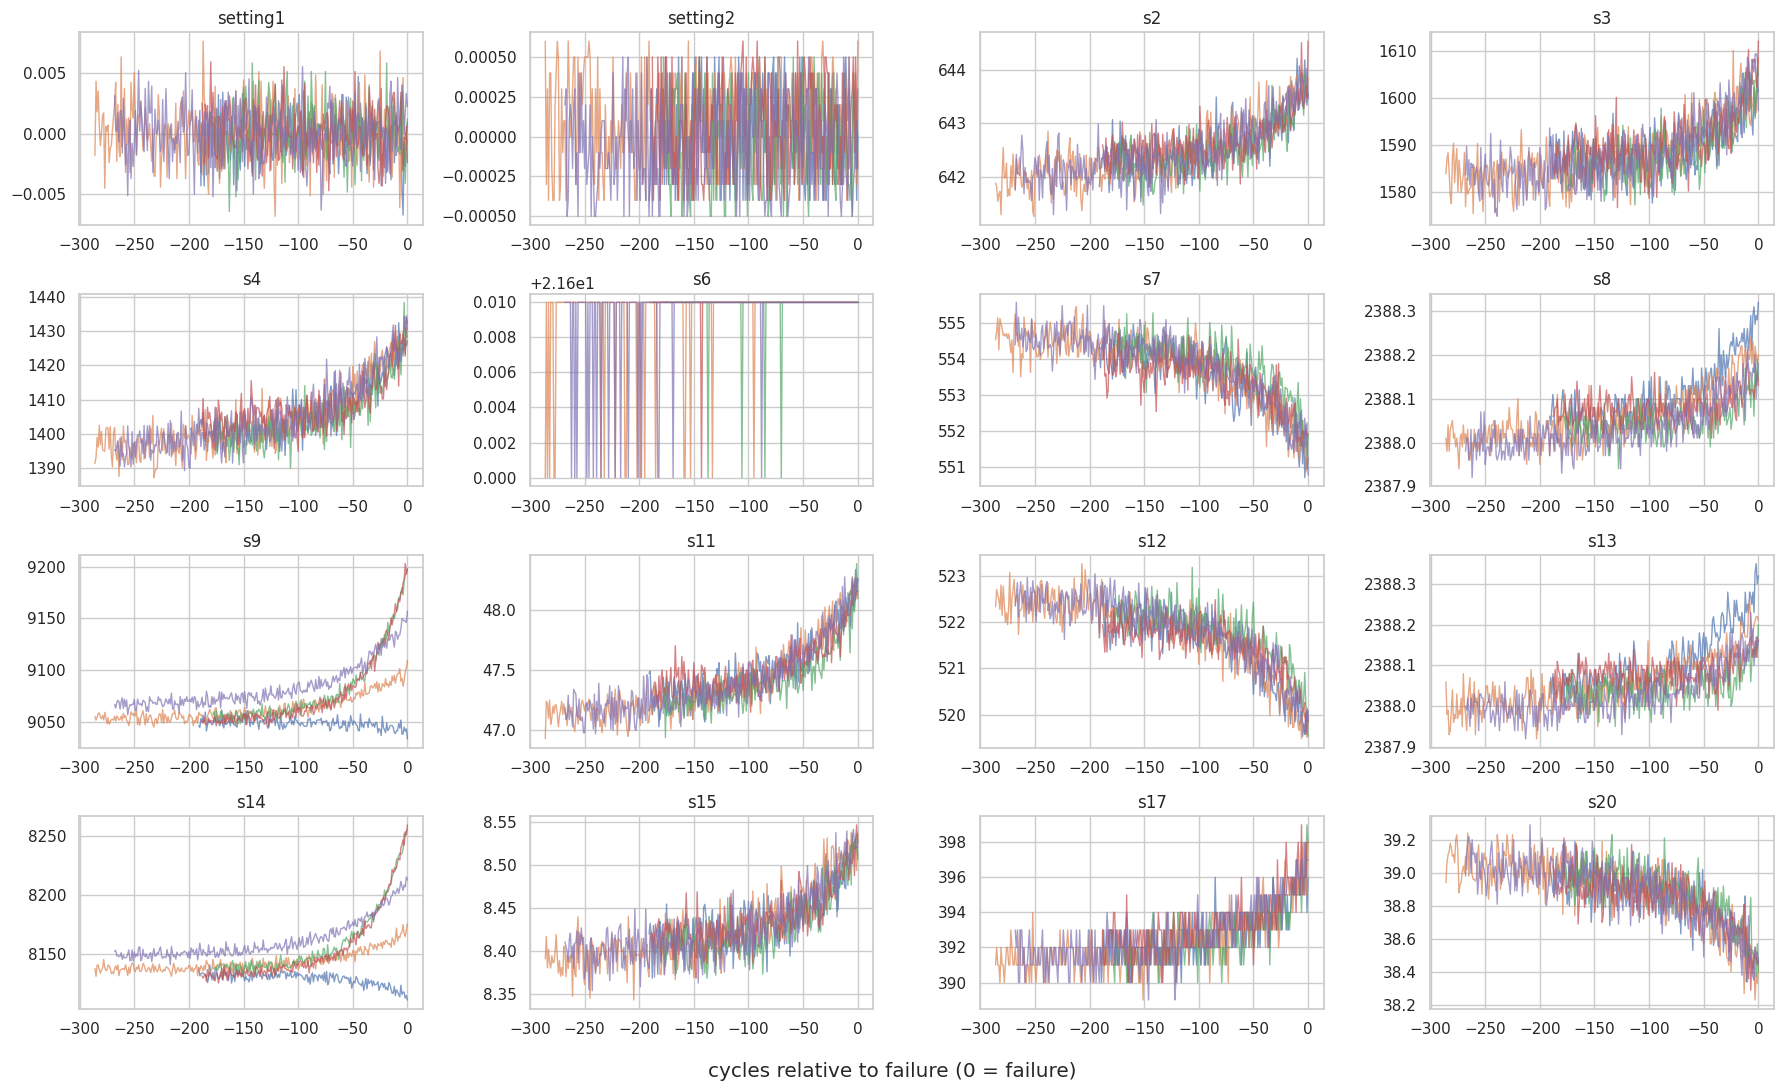

In [6]:
kept = [c for c in feat if c not in constant]
fig, axes = plt.subplots(4, 4, figsize=(18, 11)); axes = axes.ravel()
for ax, s in zip(axes, [c for c in kept if c.startswith("s")][:16]):
    for eid in (1, 2, 3, 4, 5):
        d = train[train["id"] == eid]
        ax.plot(d["cycle"] - d["cycle"].max(), d[s], alpha=0.7, lw=1)
    ax.set_title(s)
fig.supxlabel("cycles relative to failure (0 = failure)")
plt.tight_layout(); plt.show()

### 3.6 Outliers

,rows |z|>3,% rows
s9,521,2.53
s14,496,2.40
s6,406,1.97
s8,107,0.52
s13,83,0.40
s17,81,0.39
setting1,53,0.26
s3,47,0.23


Rows with at least one |z|>3 sensor value: 6.5%


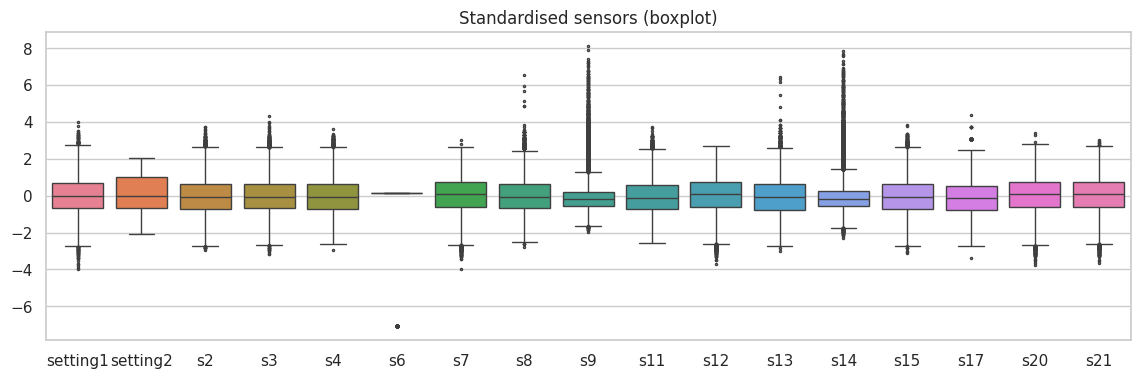

In [7]:
sens = [c for c in kept if c.startswith("s")]
z = (train[sens] - train[sens].mean()) / train[sens].std()
out = pd.DataFrame({"rows |z|>3": (z.abs() > 3).sum(),
                    "% rows": ((z.abs() > 3).mean() * 100).round(2)}).sort_values("rows |z|>3", ascending=False)
display(out.head(8))
print("Rows with at least one |z|>3 sensor value: %.1f%%" % ((z.abs() > 3).any(axis=1).mean() * 100))

fig, ax = plt.subplots(figsize=(14, 4))
sns.boxplot(data=(train[sens] - train[sens].mean()) / train[sens].std(), fliersize=1.5, ax=ax)
ax.set_title("Standardised sensors (boxplot)"); plt.show()

### 3.7 Correlations

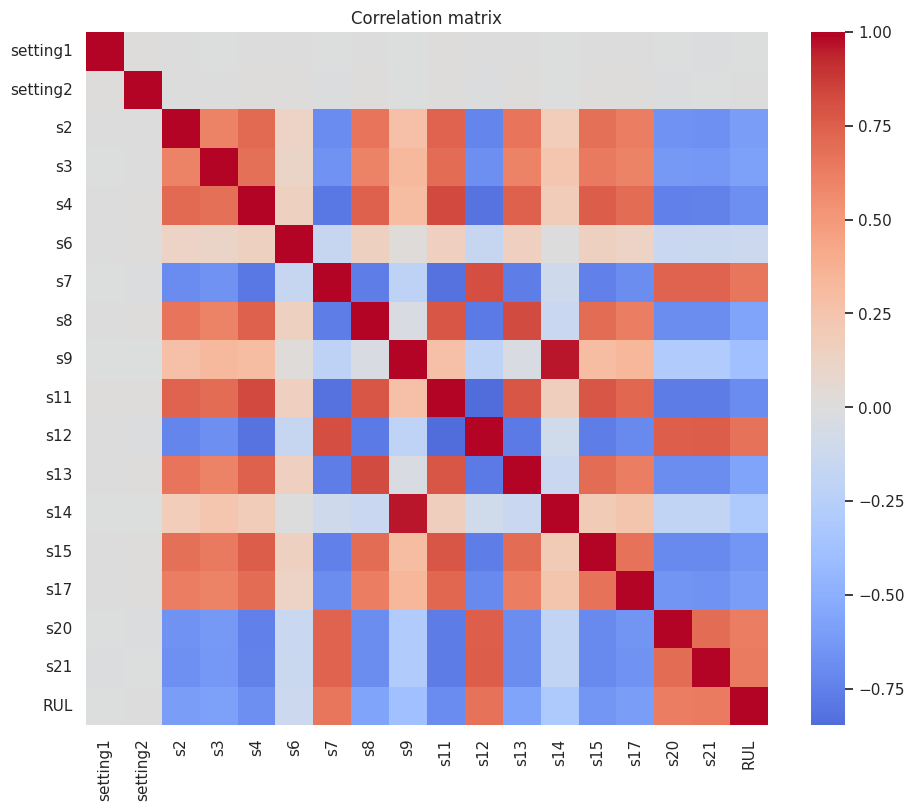

Correlation with RUL (sorted by strength):
s11        -0.70
s4         -0.68
s12         0.67
s7          0.66
s15        -0.64
s21         0.64
s20         0.63
s2         -0.61
s17        -0.61
s3         -0.58
s8         -0.56
s13        -0.56
s9         -0.39
s14        -0.31
s6         -0.13
setting1   -0.00
setting2   -0.00

Highly correlated sensor pairs (|r| > 0.95):
s9  s14    0.963


In [8]:
corr = train[kept + ["RUL"]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax); ax.set_title("Correlation matrix"); plt.show()

rul_corr = corr["RUL"].drop("RUL")
print("Correlation with RUL (sorted by strength):")
print(rul_corr.reindex(rul_corr.abs().sort_values(ascending=False).index).round(2).to_string())

pairs = corr.loc[sens, sens].abs().where(np.triu(np.ones((len(sens), len(sens))), 1).astype(bool)).stack()
print("\nHighly correlated sensor pairs (|r| > 0.95):")
print(pairs[pairs > 0.95].sort_values(ascending=False).round(3).to_string())

### 3.8 Train vs test and the settings

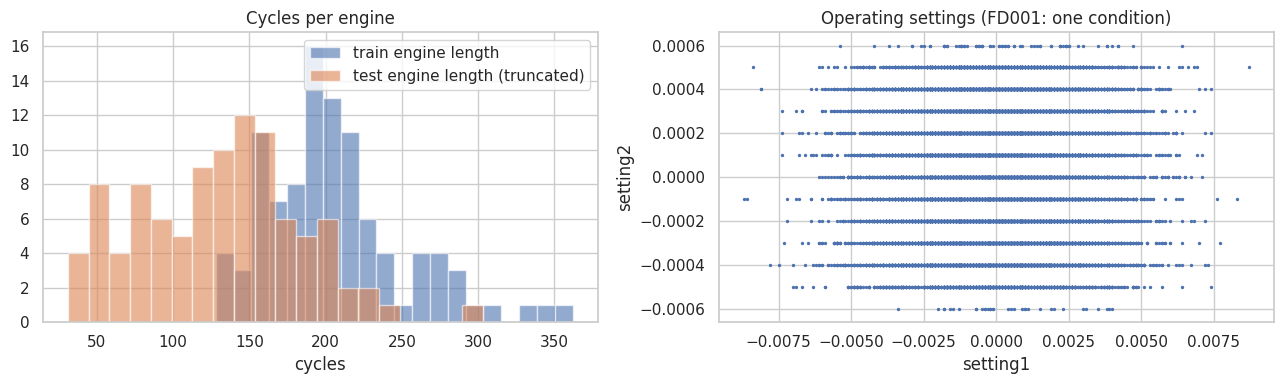

Shortest test engine: 31 cycles (window size is 30)
Test engines shorter than 30 cycles: 0
Train vs test mean difference, in train std units (largest 5):
s11    0.468
s4     0.466
s12    0.453
s7     0.440
s15    0.435


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tl = test.groupby("id")["cycle"].max()
ax[0].hist(life, bins=20, alpha=0.6, label="train engine length"); ax[0].hist(tl, bins=20, alpha=0.6, label="test engine length (truncated)")
ax[0].legend(); ax[0].set_title("Cycles per engine"); ax[0].set_xlabel("cycles")
ax[1].scatter(train["setting1"], train["setting2"], s=2); ax[1].set_title("Operating settings (FD001: one condition)")
ax[1].set_xlabel("setting1"); ax[1].set_ylabel("setting2"); plt.tight_layout(); plt.show()
print("Shortest test engine:", int(tl.min()), "cycles (window size is 30)")
print("Test engines shorter than 30 cycles:", int((tl < 30).sum()))
print("Train vs test mean difference, in train std units (largest 5):")
print(((test[kept].mean() - train[kept].mean()) / train[kept].std()).abs().sort_values(ascending=False).head(5).round(3).to_string())

## 4. Findings and decisions for the model
| # | Finding (from the outputs above) | Decision for the model |
|---|---|---|
| 1 | Training RUL runs from 0 up to the engine lifetime (128 to 362 cycles, mean about 206). The test engines are cut earlier, with true RUL between 7 and 145 (median 86). | Predict RUL at the last cycle of each window. Report RMSE on the 100 test engines. Consider capping very large RUL values when training, and say so in the report. |
| 2 | No missing values, no duplicate rows, and every engine has consecutive cycles. | No imputation and no row removal is needed. |
| 3 | 7 features never change (setting3, s1, s5, s10, s16, s18, s19), and s6 only takes 2 values. | Drop the constant features. They carry no information and can break scaling. |
| 4 | About 6.5% of rows have at least one sensor beyond 3 standard deviations (mostly s9, s14, s6). Plots show these come from the normal degradation trend and sensor noise, not from bad records. | Keep the outliers. Do not delete or clip them. Scale with StandardScaler. |
| 5 | 12 sensors correlate clearly with RUL (|r| from 0.56 to 0.70, e.g. s11, s4, s12, s7). The settings have no correlation with RUL. s9 and s14 are highly correlated with each other (0.96). | Keep the sensors, since the models can use them together. The settings carry almost no signal in FD001. |
| 6 | Single sensor values are noisy but their trend over the cycles is clear in the plots. | Use a sliding window of 30 cycles so the model sees the trend, not one noisy reading. |
| 7 | Test engines are all at least 31 cycles long, and the test sensors are slightly shifted toward the failure state, as expected from truncated histories. | A window of 30 is valid for every test engine. Fit the scaler on training engines only to avoid leakage. |
| 8 | Splitting rows at random would put cycles of the same engine in both train and validation. | Split by engine (GroupShuffleSplit), so validation engines are never seen in training. |